# MNIST: CNN versus Fully Connected Networks

**Author:** Mohammed Alaa Eddine GUERBOUZ  
**University:** University of Ghardaia — Department of Mathematics and Computer Science  
**Academic period:** Master 2 SIEC · 2024–2025  
**Type:** Original university coursework, reorganized for a GitHub portfolio in 2026

**Problem:** Classify handwritten digits and compare convolutional and dense neural networks.

**Approach:** TensorFlow/Keras CNN and FCNN implementations.

> Historical coursework: the computational cells below are retained from the original submission. Results have not been independently rerun or revalidated as part of the portfolio reorganization. See this folder's README for data and execution notes.


---

<div class="alert alert-success">

<center><b>University of Ghardaia</b></center>
    
<center><i>Faculty of Science and Technology - Department of Mathematics and Computer Science – Master 2 SIEC - 2024/2025</i>
</center></div>

------

<br><br>

<center>
<span style='font-weight:bold;font-size:27px;'><span style='color:#5D00FF;'>Mini Project  : Part 1 Project 1 FCNN </span>
    </span>
    </center>
<br>


# TP 1 AI USING FCNN
## GUERBOUZ MOHAMMED ALAA EDDINE

In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

# Load and preprocess data
mnist = tf.keras.datasets.mnist
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()
X_train, X_test = X_train / 255.0, X_test / 255.0  # Normalize pixel values to between 0 and 1
print("Training data shape:", X_train.shape)  # (60000, 28, 28)
print("Training labels shape:", Y_train.shape)  # (60000,)
print("Test data shape:", X_test.shape)  # (10000, 28, 28)
print("Test labels shape:", Y_test.shape)  # (10000,)
print("Number of classes:", len(set(Y_train)))  # 10
import numpy as np
print("Class distribution in training set:", np.bincount(Y_train))
print("Class distribution in test set:", np.bincount(Y_test))
# Flatten images
X_train_flatten = X_train.reshape(X_train.shape[0], -1)
X_test_flatten = X_test.reshape(X_test.shape[0], -1)

# Define FCNN model
fcnn_model = Sequential([
    Flatten(input_shape=(28, 28)),  # Flatten the input image
    Dense(128, activation='relu'),  # Fully connected layer with 128 neurons and ReLU activation
    Dense(64, activation='relu'),   # Fully connected layer with 64 neurons and ReLU activation
    Dense(10, activation='softmax') # Output layer with 10 neurons (for each digit) and softmax activation
])

# Compile the model
fcnn_model.compile(optimizer='adam',
                   loss='sparse_categorical_crossentropy',
                   metrics=['accuracy'])

# Train the model
fcnn_model.fit(X_train, Y_train, epochs=5)

# Evaluate the model
test_loss, test_acc = fcnn_model.evaluate(X_test, Y_test)
print("Test Loss on 10,000 test samples:", test_loss)
print("Test Accuracy on 10,000 test samples:", test_acc)


Training data shape: (60000, 28, 28)
Training labels shape: (60000,)
Test data shape: (10000, 28, 28)
Test labels shape: (10000,)
Number of classes: 10
Class distribution in training set: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]
Class distribution in test set: [ 980 1135 1032 1010  982  892  958 1028  974 1009]
Epoch 1/5
1875/1875 [==============================] - 3s 1ms/step - loss: 0.2438 - accuracy: 0.9290
Epoch 2/5
1875/1875 [==============================] - 2s 1ms/step - loss: 0.1029 - accuracy: 0.9688
Epoch 3/5
1875/1875 [==============================] - 2s 1ms/step - loss: 0.0699 - accuracy: 0.9790
Epoch 4/5
1875/1875 [==============================] - 2s 1ms/step - loss: 0.0543 - accuracy: 0.9826
Epoch 5/5
313/313 [==============================] - 0s 743us/step - loss: 0.1008 - accuracy: 0.9718
Test Loss on 10,000 test samples: 0.10076776891946793
Test Accuracy on 10,000 test samples: 0.9718000292778015


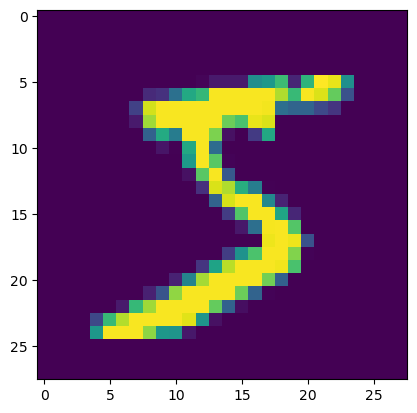

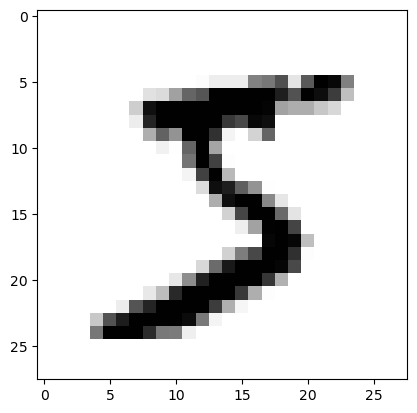

In [6]:
import cv2 
import numpy as np
import matplotlib.pyplot as plt
plt.imshow(X_train[0])
plt.show()
plt.imshow(X_train[0],cmap=plt.cm.binary)

## Download the Image to be tested out by the model its dimension is 28x28

In [7]:
img = cv2.imread('test.Png')

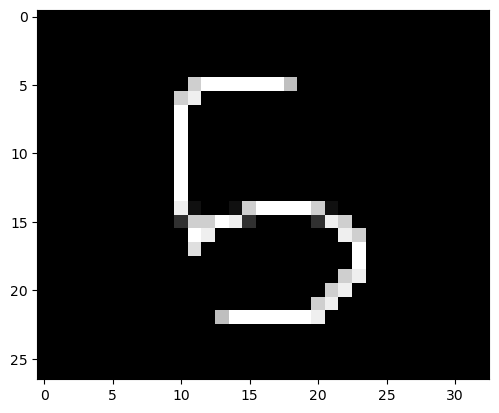

In [8]:
plt.imshow(img)

In [15]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

resized = cv2.resize(gray,(28,28), interpolation =cv2.INTER_AREA)
newimg =tf.keras.utils.normalize(resized, axis=1)
newimg = np.array(newimg).reshape(-1,28,28,1)
p= fcnn_model.predict(newimg)
print(np.argmax(p))

1/1 [==============================] - 0s 15ms/step
5
